# Auditing DP-FedAvg with Membership Inference Attacks
**Run order:** Runtime -> Change runtime type -> **T4 GPU**, then run cells top to bottom.
Set `QUICK = True` in Cell 2 first (about 5 minutes) to make sure everything works. Then set `QUICK = False` for the real run (about 40 to 60 minutes).

In [1]:
# CELL 1: install (only the privacy accountant is needed)
!pip -q install opacus

In [2]:
# CELL 2: configuration
import os, json, random, time
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from torch.nn.utils import parameters_to_vector, vector_to_parameters
import matplotlib.pyplot as plt

QUICK = False            # <- True = fast smoke test, False = real experiment

DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEV)

N_CLIENTS     = 500      # total clients
SAMPLES_EACH  = 20       # records per client -> 10,000 members in total
Q             = 0.1      # each round every client participates with prob Q (~50 clients/round)
ROUNDS        = 10 if QUICK else 100
LOCAL_EPOCHS  = 5
BATCH         = 10
LOCAL_LR      = 0.05
SERVER_LR     = 1.0
CLIP          = 1.0      # clipping norm C
DELTA         = 1e-5
SEEDS         = [0] if QUICK else [0, 1, 2]

# name -> (clip, noise_multiplier z).  clip=None means plain FedAvg (no DP at all)
CONFIGS = {
    "FedAvg":    (None, 0.0),
    "Clip-only": (CLIP, 0.0),
    "z=0.5":     (CLIP, 0.5),
    "z=1":       (CLIP, 1.0),
    "z=2":       (CLIP, 2.0),
    "z=4":       (CLIP, 4.0),
}
# ---- where results are saved ----
USE_DRIVE = True        # True = save to YOUR Google Drive (survives disconnects). False = temporary Colab disk.
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")                 # a popup asks you to allow access: click through it
    BASE = "/content/drive/MyDrive/dp_fedavg_project"
else:
    BASE = "/content/dp_fedavg_project"
RES_NAME = "results_quick" if QUICK else "results"
RES_DIR = f"{BASE}/{RES_NAME}"
FIG_DIR = f"{BASE}/figures"
os.makedirs(RES_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)
print("Results will be saved in:", BASE)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device: cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Results will be saved in: /content/drive/MyDrive/dp_fedavg_project


In [3]:
# CELL 3: data. 10k members (train), 10k non-members (attack ground truth), 10k test (utility)
import torchvision
tr = torchvision.datasets.CIFAR10("./data", train=True,  download=True)
te = torchvision.datasets.CIFAR10("./data", train=False, download=True)
X = np.concatenate([tr.data, te.data]); Y = np.concatenate([tr.targets, te.targets])
X = torch.tensor(X).permute(0, 3, 1, 2).float() / 255.0
mean = X.mean((0, 2, 3), keepdim=True); std = X.std((0, 2, 3), keepdim=True)
X = ((X - mean) / std); Y = torch.tensor(Y)

rng = np.random.RandomState(0)             # fixed split, same for every experiment
perm = rng.permutation(len(X))
n_mem = N_CLIENTS * SAMPLES_EACH
mem_idx, non_idx, test_idx = perm[:n_mem], perm[n_mem:2*n_mem], perm[2*n_mem:3*n_mem]

Xmem, Ymem = X[mem_idx].to(DEV), Y[mem_idx].to(DEV)
Xnon, Ynon = X[non_idx].to(DEV), Y[non_idx].to(DEV)
Xte,  Yte  = X[test_idx].to(DEV), Y[test_idx].to(DEV)
# IID partition: client k owns records [k*20, (k+1)*20)
client_X = [Xmem[k*SAMPLES_EACH:(k+1)*SAMPLES_EACH] for k in range(N_CLIENTS)]
client_Y = [Ymem[k*SAMPLES_EACH:(k+1)*SAMPLES_EACH] for k in range(N_CLIENTS)]
print("members", len(Xmem), "non-members", len(Xnon), "test", len(Xte))

100%|██████████| 170M/170M [19:39<00:00, 145kB/s]


members 10000 non-members 10000 test 10000


In [4]:
# CELL 4: model, DP-FedAvg, privacy accountant, attacks
class CNN(nn.Module):
    # GroupNorm instead of BatchNorm: BatchNorm mixes samples and is incompatible with DP
    def __init__(s):
        super().__init__()
        s.c1 = nn.Conv2d(3, 32, 3, padding=1);  s.n1 = nn.GroupNorm(8, 32)
        s.c2 = nn.Conv2d(32, 64, 3, padding=1); s.n2 = nn.GroupNorm(8, 64)
        s.c3 = nn.Conv2d(64, 64, 3, padding=1); s.n3 = nn.GroupNorm(8, 64)
        s.fc = nn.Linear(64 * 4 * 4, 10)
    def forward(s, x):
        x = F.max_pool2d(F.relu(s.n1(s.c1(x))), 2)
        x = F.max_pool2d(F.relu(s.n2(s.c2(x))), 2)
        x = F.max_pool2d(F.relu(s.n3(s.c3(x))), 2)
        return s.fc(x.flatten(1))

def local_train(model, gvec, Xc, Yc):
    # starts from the global weights, trains locally, returns the UPDATE (delta = w_local - w_global)
    vector_to_parameters(gvec.clone(), model.parameters())
    model.train()
    opt = torch.optim.SGD(model.parameters(), lr=LOCAL_LR)
    n = len(Xc)
    for _ in range(LOCAL_EPOCHS):
        p = torch.randperm(n, device=Xc.device)
        for i in range(0, n, BATCH):
            idx = p[i:i+BATCH]
            opt.zero_grad()
            F.cross_entropy(model(Xc[idx]), Yc[idx]).backward()
            opt.step()
    return parameters_to_vector(model.parameters()).detach() - gvec

@torch.no_grad()
def evaluate(model, gvec, Xs, Ys):
    vector_to_parameters(gvec.clone(), model.parameters()); model.eval()
    losses, correct = [], 0
    for i in range(0, len(Xs), 1000):
        out = model(Xs[i:i+1000])
        losses.append(F.cross_entropy(out, Ys[i:i+1000], reduction="none").cpu())
        correct += (out.argmax(1) == Ys[i:i+1000]).sum().item()
    return torch.cat(losses).numpy(), correct / len(Xs)

def run_fl(name, clip, z, seed):
    path = f"{RES_DIR}/{name}_seed{seed}.npz"
    if os.path.exists(path): return            # resume support if Colab disconnects
    set_seed(seed)
    model = CNN().to(DEV)
    g = parameters_to_vector(model.parameters()).detach().clone()
    t0 = time.time()
    for r in range(ROUNDS):
        sel = np.where(np.random.rand(N_CLIENTS) < Q)[0]       # Poisson client sampling
        agg = torch.zeros_like(g)
        for k in sel:
            d = local_train(model, g, client_X[k], client_Y[k])
            if clip is not None:                                # clip update to L2 norm <= C
                d = d * min(1.0, clip / (d.norm().item() + 1e-12))
            agg += d
        if clip is not None and z > 0:                          # Gaussian noise on the SUM
            agg += torch.randn_like(g) * z * clip
        g = g + SERVER_LR * agg / (Q * N_CLIENTS)               # fixed denominator = expected #clients
        if (r + 1) % 10 == 0 or r == ROUNDS - 1:
            _, acc = evaluate(model, g, Xte, Yte)
            print(f"  [{name} s{seed}] round {r+1}/{ROUNDS} test_acc={acc:.3f} ({time.time()-t0:.0f}s)")
    ml, tra = evaluate(model, g, Xmem, Ymem)
    nl, _   = evaluate(model, g, Xnon, Ynon)
    _, tea  = evaluate(model, g, Xte, Yte)
    np.savez(path, member_loss=ml, nonmember_loss=nl, train_acc=tra, test_acc=tea)

# ---------- privacy accountant (theoretical epsilon) ----------
from opacus.accountants.analysis import rdp as rdp_an
def theoretical_eps(z, q=Q, T=None, delta=DELTA):
    T = T or ROUNDS
    if z == 0: return float("inf")
    orders = [1 + x / 10 for x in range(1, 100)] + list(range(12, 64))
    r = rdp_an.compute_rdp(q=q, noise_multiplier=z, steps=T, orders=orders)
    eps, _ = rdp_an.get_privacy_spent(orders=orders, rdp=r, delta=delta)
    return float(eps)

# ---------- membership inference: loss-threshold attack ----------
from sklearn.metrics import roc_curve, roc_auc_score
from scipy.stats import beta as beta_dist
def mia_metrics(mem_loss, non_loss):
    s = -np.concatenate([mem_loss, non_loss])             # low loss => "member"
    y = np.r_[np.ones(len(mem_loss)), np.zeros(len(non_loss))]
    fpr, tpr, _ = roc_curve(y, s)
    at = lambda a: float(tpr[np.searchsorted(fpr, a, side="right") - 1])
    return dict(auc=roc_auc_score(y, s), adv=float((tpr - fpr).max()),
                tpr_1=at(0.01), tpr_10=at(0.10))

def cp_upper(k, n, a): return 1.0 if k >= n else beta_dist.ppf(1 - a, k + 1, n - k)
def cp_lower(k, n, a): return 0.0 if k <= 0 else beta_dist.ppf(a, k, n - k + 1)

def eps_lower_bound(mem_loss, non_loss, delta=DELTA, conf=0.05):
    # DP implies TPR <= e^eps * FPR + delta  =>  eps >= ln((TPR - delta) / FPR)
    # We use Clopper-Pearson confidence bounds (TPR lower, FPR upper) + Bonferroni correction.
    sp, sn = -mem_loss, -non_loss
    grid = [5, 10, 20, 50, 100, 200, 500, 1000]
    a = conf / len(grid); best = 0.0
    sn_sorted = np.sort(sn)[::-1]
    for fp in grid:
        thr = sn_sorted[fp]
        fpc, tpc = int((sn > thr).sum()), int((sp > thr).sum())
        if fpc == 0: continue
        tpr_lo, fpr_up = cp_lower(tpc, len(sp), a), cp_upper(fpc, len(sn), a)
        if tpr_lo > delta:
            best = max(best, float(np.log((tpr_lo - delta) / fpr_up)))
    return best

In [5]:
# CELL 5: run all experiments (QUICK ~5 min, full ~40-60 min). Safe to re-run: finished runs are skipped.
for seed in SEEDS:
    for name, (clip, z) in CONFIGS.items():
        print(f"=== {name} | seed {seed} ===")
        run_fl(name, clip, z, seed)
print("done")

=== FedAvg | seed 0 ===
  [FedAvg s0] round 10/100 test_acc=0.351 (16s)
  [FedAvg s0] round 20/100 test_acc=0.420 (31s)
  [FedAvg s0] round 30/100 test_acc=0.449 (47s)
  [FedAvg s0] round 40/100 test_acc=0.478 (62s)
  [FedAvg s0] round 50/100 test_acc=0.497 (77s)
  [FedAvg s0] round 60/100 test_acc=0.511 (92s)
  [FedAvg s0] round 70/100 test_acc=0.520 (107s)
  [FedAvg s0] round 80/100 test_acc=0.530 (121s)
  [FedAvg s0] round 90/100 test_acc=0.542 (136s)
  [FedAvg s0] round 100/100 test_acc=0.549 (151s)
=== Clip-only | seed 0 ===
  [Clip-only s0] round 10/100 test_acc=0.343 (15s)
  [Clip-only s0] round 20/100 test_acc=0.419 (31s)
  [Clip-only s0] round 30/100 test_acc=0.449 (47s)
  [Clip-only s0] round 40/100 test_acc=0.476 (63s)
  [Clip-only s0] round 50/100 test_acc=0.498 (77s)
  [Clip-only s0] round 60/100 test_acc=0.512 (92s)
  [Clip-only s0] round 70/100 test_acc=0.521 (106s)
  [Clip-only s0] round 80/100 test_acc=0.527 (120s)
  [Clip-only s0] round 90/100 test_acc=0.538 (135s)
  

In [6]:
# CELL 6: results table (paste this into your report)
rows = []
for name, (clip, z) in CONFIGS.items():
    per = []
    for s in SEEDS:
        d = np.load(f"{RES_DIR}/{name}_seed{s}.npz")
        m = mia_metrics(d["member_loss"], d["nonmember_loss"])
        m["eps_emp"] = eps_lower_bound(d["member_loss"], d["nonmember_loss"])
        m["test_acc"] = float(d["test_acc"]); m["train_acc"] = float(d["train_acc"])
        per.append(m)
    df = pd.DataFrame(per)
    row = {"config": name, "eps_theory": round(theoretical_eps(z), 2) if clip is not None else float("inf")}
    for c in ["test_acc", "train_acc", "auc", "tpr_1", "tpr_10", "adv", "eps_emp"]:
        row[c] = f"{df[c].mean():.3f} ± {df[c].std(ddof=0):.3f}"
    rows.append(row)
table = pd.DataFrame(rows)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)
print(table.to_string(index=False))
table.to_csv(f"{BASE}/results_table.csv", index=False)
print("Saved to", f"{BASE}/results_table.csv")

   config  eps_theory      test_acc     train_acc           auc         tpr_1        tpr_10           adv       eps_emp
   FedAvg         inf 0.538 ± 0.008 0.613 ± 0.006 0.544 ± 0.002 0.012 ± 0.001 0.113 ± 0.003 0.077 ± 0.001 0.002 ± 0.002
Clip-only         inf 0.538 ± 0.008 0.611 ± 0.009 0.544 ± 0.002 0.013 ± 0.001 0.114 ± 0.001 0.074 ± 0.002 0.001 ± 0.001
    z=0.5       35.23 0.443 ± 0.004 0.480 ± 0.009 0.526 ± 0.001 0.011 ± 0.002 0.108 ± 0.002 0.044 ± 0.003 0.000 ± 0.000
      z=1        7.90 0.346 ± 0.007 0.373 ± 0.004 0.516 ± 0.000 0.011 ± 0.001 0.105 ± 0.003 0.031 ± 0.001 0.000 ± 0.000
      z=2        2.58 0.251 ± 0.006 0.261 ± 0.003 0.510 ± 0.002 0.012 ± 0.001 0.105 ± 0.000 0.020 ± 0.004 0.000 ± 0.000
      z=4        1.08 0.162 ± 0.015 0.165 ± 0.018 0.503 ± 0.004 0.010 ± 0.000 0.103 ± 0.004 0.013 ± 0.005 0.000 ± 0.000
Saved to /content/drive/MyDrive/dp_fedavg_project/results_table.csv


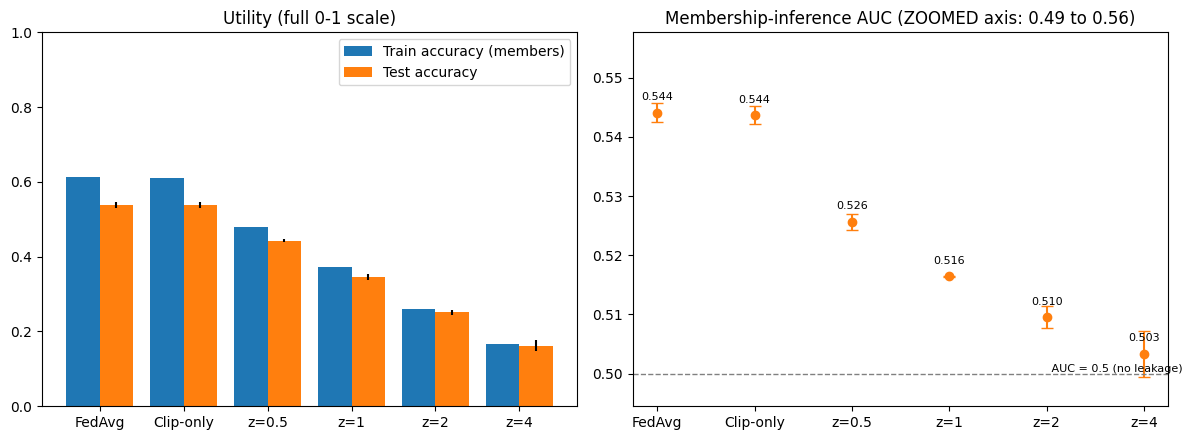

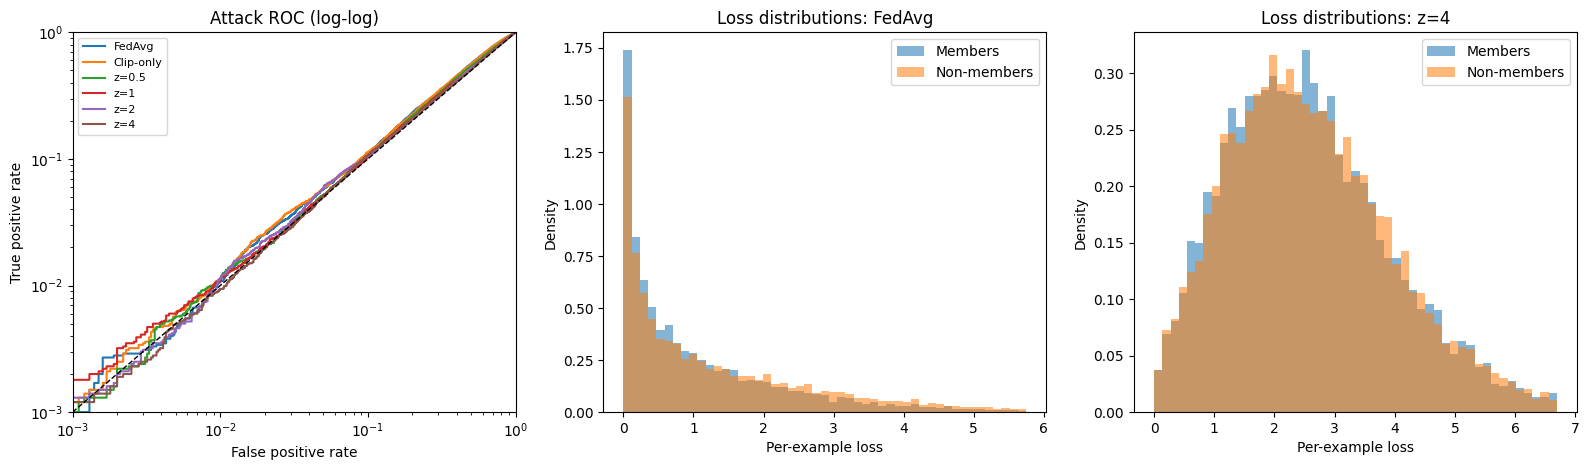

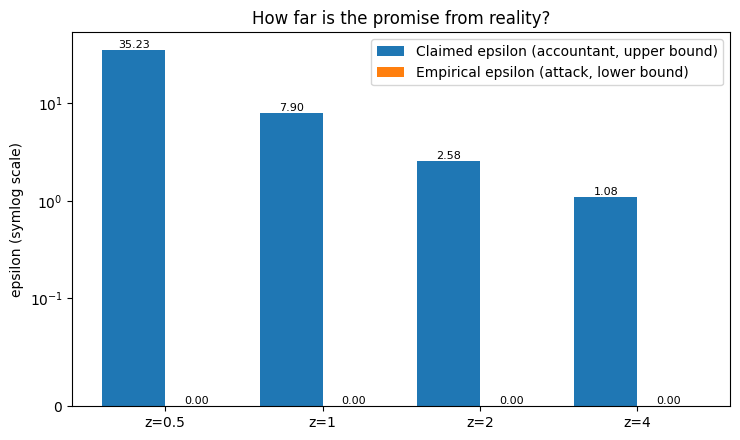

In [10]:
# CELL 7: figures
names = list(CONFIGS)
stats = {}
for n in names:
    v = {k: [] for k in ["test_acc", "train_acc", "auc", "tpr_1", "eps_emp"]}
    for s_ in SEEDS:
        d = np.load(f"{RES_DIR}/{n}_seed{s_}.npz")
        m = mia_metrics(d["member_loss"], d["nonmember_loss"])
        v["test_acc"].append(float(d["test_acc"])); v["train_acc"].append(float(d["train_acc"]))
        v["auc"].append(m["auc"]); v["tpr_1"].append(m["tpr_1"])
        v["eps_emp"].append(eps_lower_bound(d["member_loss"], d["nonmember_loss"]))
    stats[n] = {k: (np.mean(x), np.std(x)) for k, x in v.items()}
mu = lambda k: np.array([stats[n][k][0] for n in names]); sd = lambda k: np.array([stats[n][k][1] for n in names])
x = np.arange(len(names))

# Fig 1: left = utility on the full 0-1 scale, right = leakage on a ZOOMED axis (clearly labelled)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(x - 0.2, mu("train_acc"), 0.4, label="Train accuracy (members)")
ax[0].bar(x + 0.2, mu("test_acc"), 0.4, yerr=sd("test_acc"), label="Test accuracy")
ax[0].set_ylim(0, 1); ax[0].set_xticks(x); ax[0].set_xticklabels(names); ax[0].legend(); ax[0].set_title("Utility (full 0-1 scale)")
a, e = mu("auc"), sd("auc")
ax[1].errorbar(x, a, yerr=e, fmt="o", capsize=4, color="C1")
for xi, ai in zip(x, a): ax[1].annotate(f"{ai:.3f}", (xi, ai), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8)
ax[1].axhline(0.5, color="gray", ls="--", lw=1); ax[1].text(len(names) - 0.6, 0.5, " AUC = 0.5 (no leakage)", va="bottom", ha="right", fontsize=8)
lo, hi = min(0.495, (a - e).min() - 0.005), (a + e).max() + 0.012
ax[1].set_ylim(lo, hi); ax[1].set_xticks(x); ax[1].set_xticklabels(names)
ax[1].set_title("Membership-inference AUC (ZOOMED axis: %.2f to %.2f)" % (lo, hi))
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig1_utility_vs_leakage.png", dpi=200); plt.show()

# Fig 2: ROC curves on log-log axes (seed 0) + loss distributions for FedAvg vs the noisiest run
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for n in names:
    d = np.load(f"{RES_DIR}/{n}_seed{SEEDS[0]}.npz")
    sc = -np.concatenate([d["member_loss"], d["nonmember_loss"]])
    y = np.r_[np.ones(len(d["member_loss"])), np.zeros(len(d["nonmember_loss"]))]
    f, t, _ = roc_curve(y, sc); ax[0].plot(f, t, label=n)
ax[0].plot([1e-3, 1], [1e-3, 1], "k--", lw=1)
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlim(1e-3, 1); ax[0].set_ylim(1e-3, 1)
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].legend(fontsize=8); ax[0].set_title("Attack ROC (log-log)")
for axi, n in zip(ax[1:], [names[0], names[-1]]):
    d = np.load(f"{RES_DIR}/{n}_seed{SEEDS[0]}.npz")
    hi_l = np.percentile(np.r_[d["member_loss"], d["nonmember_loss"]], 99)
    bins = np.linspace(0, hi_l, 50)
    axi.hist(d["member_loss"], bins=bins, alpha=0.55, density=True, label="Members")
    axi.hist(d["nonmember_loss"], bins=bins, alpha=0.55, density=True, label="Non-members")
    axi.set_xlabel("Per-example loss"); axi.set_ylabel("Density"); axi.set_title(f"Loss distributions: {n}"); axi.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig2_roc_and_loss_hist.png", dpi=200); plt.show()

# Fig 3: claimed epsilon (upper bound) vs empirical epsilon (lower bound)
dp = [n for n in names if CONFIGS[n][0] is not None and CONFIGS[n][1] > 0]
th = [theoretical_eps(CONFIGS[n][1]) for n in dp]; em = [stats[n]["eps_emp"][0] for n in dp]
xx = np.arange(len(dp)); plt.figure(figsize=(7.5, 4.5))
b1 = plt.bar(xx - 0.2, th, 0.4, label="Claimed epsilon (accountant, upper bound)")
b2 = plt.bar(xx + 0.2, em, 0.4, label="Empirical epsilon (attack, lower bound)")
for r in list(b1) + list(b2): plt.annotate(f"{r.get_height():.2f}", (r.get_x() + r.get_width() / 2, r.get_height()), ha="center", va="bottom", fontsize=8)
plt.yscale("symlog", linthresh=0.1); plt.ylim(bottom=0)
plt.xticks(xx, dp); plt.ylabel("epsilon (symlog scale)"); plt.legend(); plt.title("How far is the promise from reality?")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig3_audit_gap.png", dpi=200); plt.show()

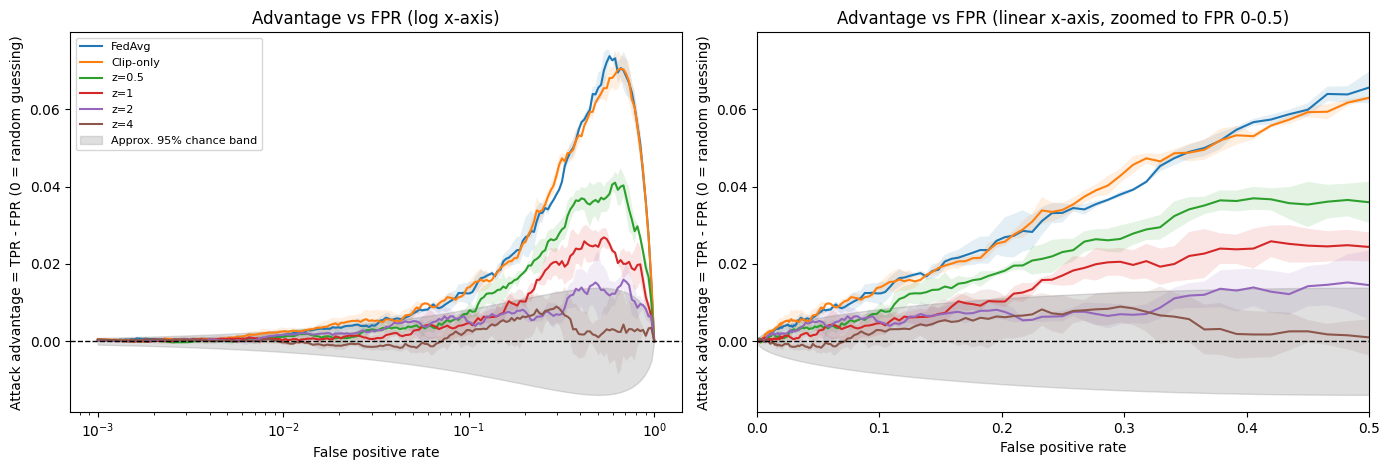

In [11]:
# CELL 7b: ROC "advantage" curves (TPR minus FPR) with a chance band. Add as a NEW cell below Cell 7.
names = list(CONFIGS)
grid = np.logspace(-3, 0, 200)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for n in names:
    curves = []
    for s_ in SEEDS:
        d = np.load(f"{RES_DIR}/{n}_seed{s_}.npz")
        sc = -np.concatenate([d["member_loss"], d["nonmember_loss"]])
        y = np.r_[np.ones(len(d["member_loss"])), np.zeros(len(d["nonmember_loss"]))]
        f, t, _ = roc_curve(y, sc)
        curves.append(np.interp(grid, f, t) - grid)          # advantage = TPR - FPR at each FPR
    m, sd_ = np.mean(curves, 0), np.std(curves, 0)
    for a_ in ax:
        a_.plot(grid, m, label=n)
        if len(SEEDS) > 1: a_.fill_between(grid, m - sd_, m + sd_, alpha=0.12)
n_neg = len(np.load(f"{RES_DIR}/{names[0]}_seed{SEEDS[0]}.npz")["nonmember_loss"])
band = 1.96 * np.sqrt(2 * grid * (1 - grid) / n_neg)         # approx. 95% range of pure chance
for a_ in ax:
    a_.fill_between(grid, -band, band, color="gray", alpha=0.25, label="Approx. 95% chance band")
    a_.axhline(0, color="k", lw=1, ls="--")
    a_.set_xlabel("False positive rate"); a_.set_ylabel("Attack advantage = TPR - FPR (0 = random guessing)")
ax[0].set_xscale("log"); ax[0].set_title("Advantage vs FPR (log x-axis)"); ax[0].legend(fontsize=8)
ax[1].set_xlim(0, 0.5); ax[1].set_title("Advantage vs FPR (linear x-axis, zoomed to FPR 0-0.5)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig2b_advantage_curve.png", dpi=200); plt.show()

In [8]:
# CELL 8: download everything
!cd {BASE} && zip -rq /content/deliverables.zip results_table.csv figures {RES_NAME}
from google.colab import files
files.download("deliverables.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>